In [1]:
using Revise
using LinearAlgebra
using NLsolve
using Plots
using LaTeXStrings

gr();
# pyplot();
# plotlyjs();

In [2]:
BLAS.set_num_threads(1)

In [3]:
using GaussianSpectralDensities

# Dynamics of a random neural network with one planted memory

$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
$$

$$
\begin{aligned}
\frac{d x_i}{dt} &= -x_i + \sum_{j = 1}^N \tilde{J}_{ij} \tanh x_j \ , \\
\tilde{J} &= \frac{\hat{\bm{x}} \tanh \hat{\bm{x}}}{\|\tanh \hat{\bm{x}}\|^2} + \sigma J \, , \\
\langle J_{ij} J_{kl} \rangle &= \frac{1}{N} \left(\delta_{ik} \delta_{jl} + \tau \delta_{il} \delta_{kj} \right) \, .
\end{aligned}
$$

The memory $\hat{\bm{x}}$ is a randomly sampled vector, and the model
is set up such that, in the absence of coupling noise ($\sigma = 0$),
there is a fixed point at $\bm{x} = \hat{\bm{x}}$. What happens as
noise is turned on, and what is the effect of symmetry $\tau$?

Note that the $\tanh$ breaks rotational symmetry, so different
$\hat{\bm{x}}$ with the same norm do not necessarily give equivalent
dynamics. Should this inform our choice of measure for sampling
memories? No, I think sampling something like a Gaussian $\hat{\bm{x}}$
is the most sensible approach. It maintains permutation invariance
but not full rotational invariance, which actually seems desirable in
a nonlinear model.

Let's run some simulations.

In [4]:
function network_f!(dx, x, J̃, t)
    mul!(dx, J̃, tanh.(x))
    dx .-= x
end

function network_jac!(jac, x, J̃, t)
    for j in 1:length(x)
        for i in 1:length(x)
            jac[i, j] = J̃[i, j] / (cosh(x[j])^2)
        end
        jac[j, j] -= one(eltype(jac))
    end
end

function poor_mans_network_jac!(jac, x, J̃, t, dx)
    xx = copy(x)
    fx = similar(xx)
    fxdx = similar(xx)
    network_f!(fx, xx, J̃, t)
    for j in 1:N
        xx[j] += dx
        network_f!(fxdx, xx, J̃, t) 
        jac[:, j] = (fxdx - fx) / (xx[j] - x[j])
        xx[j] = x[j]
    end
end

poor_mans_network_jac! (generic function with 1 method)

In [5]:
ftype = Float64

N = 256
s = one(ftype)
x̂ = s * randn(ftype, N)
tx̂ = tanh.(x̂)
Ĵ = x̂ * tx̂' / dot(tx̂, tx̂)
Ĵ[diagind(Ĵ)] .= zero(ftype);

In [6]:
σ = ftype(0.4)
τ = ftype(0.5)

J = ftype(1 / sqrt(N)) * randn(ftype, N, N)
J = SamplingUtils.partially_hermitize(J, τ)
J[diagind(J)] .= zero(ftype)

J̃ = Ĵ + σ * J;

In [7]:
# Verify Jacobian
jaca = similar(J̃)
jacb = similar(J̃)
network_jac!(jaca, x̂, J̃, zero(ftype))
poor_mans_network_jac!(jacb, x̂, J̃, zero(ftype), sqrt(eps(ftype)))
opnorm(jacb - jaca)

6.404682239256973e-7

In [8]:
sol = nlsolve(
    (dx, x) -> network_f!(dx, x, J̃, zero(ftype)),
    (jac, x) -> network_jac!(jac, x, J̃, zero(ftype)),
    x̂;
    method=:newton,
    ftol=sqrt(eps(ftype)),
)
if !converged(sol)
    error("failed to converge")
end
x₀ = sol.zero
jac = similar(J̃)
network_jac!(jac, x₀, J̃, zero(ftype))
jacevs = eigvals(jac)
println(maximum(real(jacevs)))

-0.5324477929819558


In [9]:
R = Diagonal(cosh.(x₀).^(-2))
ensemble = MatrixEnsemble(Ĵ * R - I, σ * I, R, τ)
Mevs = unique(eigvals(ensemble.M))
_J = ftype(1 / sqrt(N)) * randn(ftype, N, N)
_J = SamplingUtils.partially_hermitize(_J, τ)
Aevs = eigvals(ensemble.M + (ensemble.L * _J * ensemble.R));

In [10]:
using LazySets: VPolygon, Bloating, overapproximate, radius

coords = reinterpret(ftype, reshape(Aevs, 1, :));
region = VPolygon(coords);
region = Bloating(region, ftype(0.125) * radius(region));
region = overapproximate(region, ftype(0.01) * radius(region));
bounds = overapproximate(region);

xcenter, ycenter = bounds.center;
xradius, yradius = bounds.radius;
xmin, xmax = xcenter - xradius, xcenter + xradius;
ymin, ymax = ycenter - yradius, ycenter + yradius;
xs = range(xmin, xmax; length=round(Int, 128 * xradius));
ys = range(ymin, ymax; length=round(Int, 128 * yradius));
zs = [[x, y] in region ? complex(x, y) : missing for y in ys, x in xs];

In [11]:
i, j = 13, 62
za = zs[i, j - 1]
zb = zs[i - 1, j]
zc = zs[i, j];

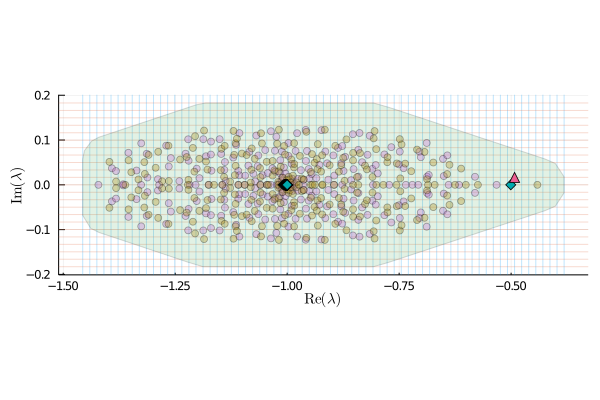

In [12]:
p = vline(xs, label="", alpha=0.25, xlims=(xs[1], xs[end]))
hline!(p, ys, label="", alpha=0.25, ylims=(ys[1], ys[end]))
plot!(
    p,
    region,
    alpha=0.15,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

scatter!(p, real(jacevs), imag(jacevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Aevs), imag(Aevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label="")

scatter!(p, xs[[j]], ys[[i]], markershape=:utriangle, markersize=5, label="")

In [13]:
objective = Fixk();
algorithm = Rampδ²(sqrt(2), 16, -16);

In [14]:
verbosity = 3;

solver = SpectralSolver(ensemble, objective, algorithm);
solutiona = solve!(solver, za; verbosity=verbosity, store_trace=true);
solutionb = solve!(solver, zb; verbosity=verbosity, store_trace=true);
qa, δa² = solutiona.q, solutiona.δ²;
qb, δb² = solutionb.q, solutionb.δ²;
qc, δc² = GaussianSpectralDensities.select(qa, qb, δa², δb²);
GaussianSpectralDensities.print_q(qc);
GaussianSpectralDensities.print_δ²(δc²);
solutionc = solve!(
    solver, zc,
    qc, δc²;
    verbosity=verbosity, store_trace=true,
);
solver = nothing;  # Hand workspace over to GC

 z = -0.508 + i 0.017
-------------------------------------------------------------------
    μ       γ²         δ²                  q                k
-------  ----------  ---------  ------------------------  ---------
  1.000   2.560e+02  2.560e+02   7.349e-03 + i-2.492e-04  3.600e-03
  1.000   1.810e+02  1.810e+02   9.805e-03 + i-3.330e-04  5.004e-03
  1.000   1.280e+02  1.280e+02   1.302e-02 + i-4.433e-04  6.934e-03
  1.000   9.050e+01  9.051e+01   1.722e-02 + i-5.877e-04  9.568e-03
  1.000   6.399e+01  6.400e+01   2.263e-02 + i-7.754e-04  1.314e-02
  1.000   4.525e+01  4.525e+01   2.955e-02 + i-1.018e-03  1.794e-02
  1.000   3.199e+01  3.200e+01   3.831e-02 + i-1.328e-03  2.431e-02
  1.000   2.262e+01  2.263e+01   4.924e-02 + i-1.722e-03  3.270e-02
  1.000   1.599e+01  1.600e+01   6.267e-02 + i-2.217e-03  4.355e-02
  1.000   1.130e+01  1.131e+01   7.891e-02 + i-2.833e-03  5.738e-02
  1.000   7.984e+00  8.000e+00   9.814e-02 + i-3.588e-03  7.466e-02
  1.000   5.637e+00  5.657e+00  

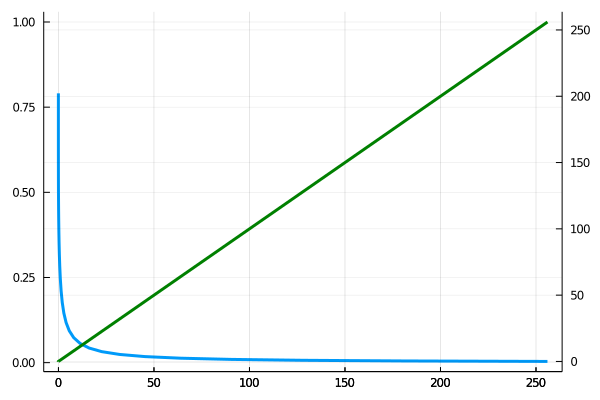

In [15]:
sol = solutionb

plot(sol.trace.γ², sol.trace.k, lw=3, label="")
scatter!([sol.γ²], [sol.k], label="")
plot!(twinx(), sol.trace.γ², sol.trace.δ², lw=3, color=:green, label="")

In [16]:
problem = SpectralProblem(zs, objective, ensemble);
solution = solve(problem, algorithm; chunks_per_thread=1);

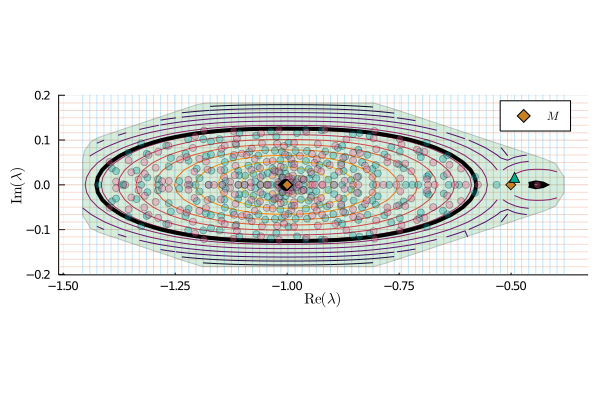

In [17]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
plot!(
    p,
    region,
    alpha=0.2,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

contour!(p, xs, ys, solution.γ², colorbar=false)
contour!(p, xs, ys, solution.γ², levels=[0.0], color=:black, linewidth=4)

scatter!(p, real(jacevs), imag(jacevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Aevs), imag(Aevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label=L"M")

scatter!(p, xs[[j]], ys[[i]], markershape=:utriangle, markersize=5, label="")

vline!([0.0], color=:black, label="")

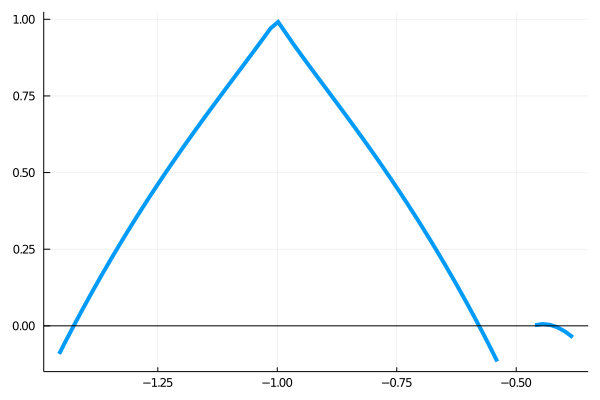

In [18]:
midi = cld(length(ys), 2)
p = plot(xs, solution.γ²[midi, :], linewidth=4, label="")
hline!(p, [0.0], color=:black, label="")

In [19]:
function fpoint(J̃, x₀)
    ftype = eltype(x₀)
    sol = nlsolve(
        (dx, x) -> network_f!(dx, x, J̃, zero(ftype)),
        (jac, x) -> network_jac!(jac, x, J̃, zero(ftype)),
        x₀;
        method=:newton,
        ftol=sqrt(eps(ftype)),
    )
    if !converged(sol)
        error("failed to converge")
    end
    return sol.zero
end

fpoint (generic function with 1 method)

In [20]:
x₀ = x̂
jac_ = similar(J̃)
σs = ftype(0.0):ftype(0.01):ftype(1.5)
evmaxs = fill(ftype(NaN), length(σs))
x₀s = fill(ftype(NaN), (length(x₀), length(σs)))
for (i, σ) in enumerate(σs)
    J̃ = Ĵ + σ * J
    x₀s[:, i] = x₀ = fpoint(J̃, x₀)
    network_jac!(jac_, x₀, J̃, zero(ftype))
    evmaxs[i] = maximum(real(eigvals(jac_)))
end

LoadError: failed to converge

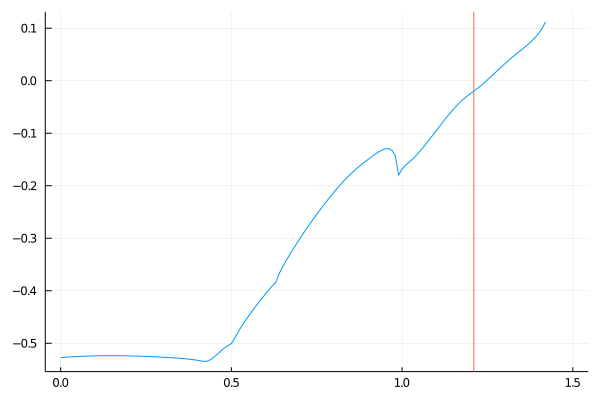

In [21]:
vl = [1.21]
plot(σs, evmaxs, label="")
vline!(vl, label="")

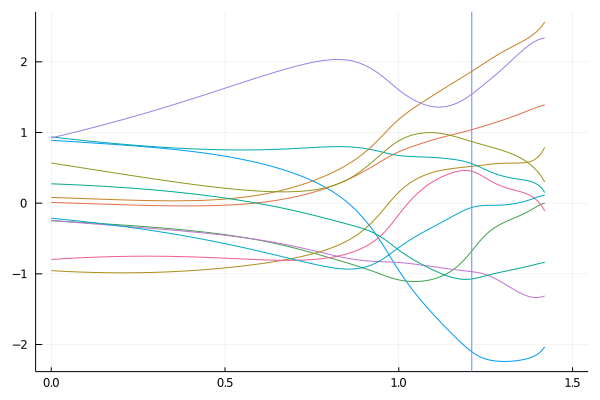

In [22]:
plot(σs, x₀s[1:12, :]', label="")
vline!(vl, label="")

In [23]:
println(repr("text/plain", [σs evmaxs]))

151×2 Array{Float64,2}:
 0.0    -0.527271
 0.01   -0.52679
 0.02   -0.526344
 0.03   -0.525933
 0.04   -0.525557
 0.05   -0.525216
 0.06   -0.52491
 0.07   -0.524639
 0.08   -0.524402
 0.09   -0.524199
 0.1    -0.524031
 0.11   -0.523895
 0.12   -0.523792
 0.13   -0.523721
 0.14   -0.523681
 0.15   -0.523673
 0.16   -0.523693
 0.17   -0.523743
 0.18   -0.523821
 0.19   -0.523926
 0.2    -0.524057
 0.21   -0.524212
 0.22   -0.524392
 0.23   -0.524595
 0.24   -0.524819
 0.25   -0.525065
 0.26   -0.525331
 0.27   -0.525617
 0.28   -0.525922
 0.29   -0.526246
 0.3    -0.526591
 0.31   -0.526957
 0.32   -0.527346
 0.33   -0.527762
 0.34   -0.528211
 0.35   -0.528702
 0.36   -0.529246
 0.37   -0.529862
 0.38   -0.530576
 0.39   -0.531425
 0.4    -0.532448
 0.41   -0.533628
 0.42   -0.534606
 0.43   -0.534081
 0.44   -0.530947
 0.45   -0.525976
 0.46   -0.520211
 0.47   -0.514303
 0.48   -0.508771
 0.49   -0.504482
 0.5    -0.500566
 0.51   -0.4903
 0.52   -0.478246
 0.53   -0.467732
 0.54   